In [4]:
import pandas as pd
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import LabelEncoder


In [2]:
df = pd.read_csv('/content/diabetes.csv')

In [3]:
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [5]:
le = {}
df_enc = df.copy()
for col in df.columns:
  le[col] = LabelEncoder()
  df_enc[col] = le[col].fit_transform(df[col])

In [7]:
df_enc

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,86,22,28,0,123,350,29,1
1,1,23,19,22,0,62,196,10,0
2,8,121,17,0,0,30,368,11,1
3,1,27,19,16,62,77,53,0,0
4,0,75,4,28,102,209,514,12,1
...,...,...,...,...,...,...,...,...,...
763,10,39,25,41,108,118,55,42,0
764,2,60,21,20,0,155,187,6,0
765,5,59,22,16,71,58,115,9,0
766,1,64,14,0,0,95,195,26,1


In [10]:
x =  df_enc[['Pregnancies','Glucose','BloodPressure','SkinThickness','Insulin','BMI','DiabetesPedigreeFunction','Age']]
y = df_enc['Outcome']

In [11]:
x

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,86,22,28,0,123,350,29
1,1,23,19,22,0,62,196,10
2,8,121,17,0,0,30,368,11
3,1,27,19,16,62,77,53,0
4,0,75,4,28,102,209,514,12
...,...,...,...,...,...,...,...,...
763,10,39,25,41,108,118,55,42
764,2,60,21,20,0,155,187,6
765,5,59,22,16,71,58,115,9
766,1,64,14,0,0,95,195,26


In [12]:
y

,Outcome
0,1
1,0
2,1
3,0
4,1
...,...
763,0
764,0
765,0
766,1


In [13]:
model = CategoricalNB()
model.fit(x,y)

CategoricalNB()

In [15]:
test = [['6','86','22','28','0','123','350','29']]

In [16]:
test

[['6', '86', '22', '28', '0', '123', '350', '29']]

In [21]:
print("\n---prediction-----------------------------------")
for t in test:

    t_numeric = [int(val) for val in t]
    row_df = pd.DataFrame([[t_numeric[0], t_numeric[1], t_numeric[2], t_numeric[3], t_numeric[4], t_numeric[5], t_numeric[6], t_numeric[7]]], columns=x.columns)

    pred = le['Outcome'].inverse_transform(model.predict(row_df))[0]
    prob = model.predict_proba(row_df)[0]

    orig_preg = le['Pregnancies'].inverse_transform([int(t[0])])[0]
    orig_gluc = le['Glucose'].inverse_transform([int(t[1])])[0]
    orig_bp = le['BloodPressure'].inverse_transform([int(t[2])])[0]
    orig_skin = le['SkinThickness'].inverse_transform([int(t[3])])[0]

    print(f"input : Pregnancies = {orig_preg}, Glucose = {orig_gluc}, BloodPressure = {orig_bp}, SkinThickness = {orig_skin}")
    print(f"output : Outcome = {pred}")
    print(f"p(No) = {prob[0]:.4f}")
    print(f"p(Yes) = {prob[1]:.4f}")


---prediction-----------------------------------
input : Pregnancies = 6, Glucose = 148, BloodPressure = 72, SkinThickness = 35
output : Outcome = 1
p(No) = 0.0380
p(Yes) = 0.9620


In [22]:
from sklearn.metrics import accuracy_score
y_pred = model.predict(x)
print(f"\n Training accuracy: {accuracy_score(y, y_pred)*100:.2f}%")


 Training accuracy: 92.84%


/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


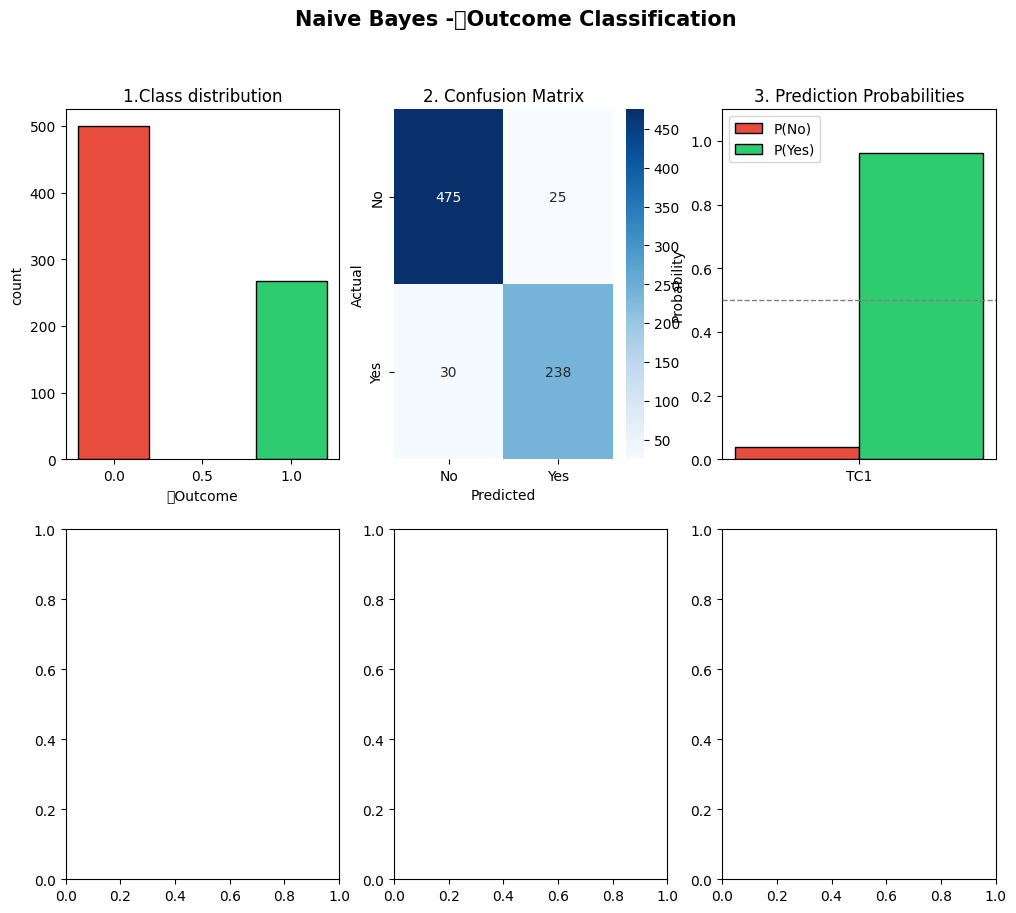

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix
#1.
fig, axes = plt.subplots(2, 3, figsize=(12, 10))
fig.suptitle("Naive Bayes -	Outcome Classification", fontsize=15, fontweight='bold')

counts = df['Outcome'].value_counts()
axes[0, 0].bar(counts.index, counts.values, color=['#e74c3c', '#2ecc71'], edgecolor='black', width=0.4)
axes[0, 0].set_title("1.Class distribution")
axes[0, 0].set_xlabel("	Outcome")
axes[0, 0].set_ylabel("count")

cm = confusion_matrix(y, model.predict(x))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No', 'Yes'],
            yticklabels=['No', 'Yes'], ax=axes[0, 1])
axes[0, 1].set_title("2. Confusion Matrix")
axes[0, 1].set_xlabel("Predicted")
axes[0, 1].set_ylabel("Actual")

#3.
test_cases = test
probs_no = [prob[0]]
probs_yes = [prob[1]]

tc_labels = [f"TC{i+1}" for i in range(len(test_cases))]
x_indices = np.arange(len(tc_labels))
w = 0.3

axes[0, 2].bar(x_indices - w/2, probs_no, w, label='P(No)',
              color='#e74c3c', edgecolor='black')
axes[0, 2].bar(x_indices + w/2, probs_yes, w, label='P(Yes)',
              color='#2ecc71', edgecolor='black')
axes[0, 2].axhline(0.5, color='gray', linestyle='--', linewidth=1)
axes[0, 2].set_title("3. Prediction Probabilities")
axes[0, 2].set_xticks(x_indices)
axes[0, 2].set_xticklabels(tc_labels)
axes[0, 2].set_ylabel("Probability")
axes[0, 2].set_ylim(0, 1.1)
axes[0, 2].legend()

plt.show()